In [9]:
#Import libraries and load dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

# Upload dataset
uploaded = files.upload()

# Load dataset
df = pd.read_csv("/content/placement_predict_50k Dataset (1).csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Saving student_placement_prediction_skillbridge_raw.csv to student_placement_prediction_skillbridge_raw (1).csv
Dataset loaded successfully!
Shape: (50000, 32)


,StudentID,Gender,City,CollegeTier,Stream,Specialisation,Hostel,HistoryOfBacklogs,SGPA_Sem1,SGPA_Sem2,...,Publications,AptitudeTestScore,SoftSkillsRating,CodingTestScore,MockInterviewScore,ExtraCurricular,CGPA_Tier,PlacementStatus,IsAnomaly,Salary Package
0,1,Male,Ahmedabad,Tier2,ECE,Networking,No,No,6.02,6.54,...,0,66.7,2.2,49.4,47.8,0,Low,0,0,0.00
1,2,Female,Mumbai,Tier2,ECE,DataScience,Yes,Yes,5.84,5.12,...,0,48.2,2.4,26.7,25.8,0,Low,0,0,0.00
2,3,Male,Kolkata,Tier2,IT,DataScience,Yes,No,4.91,5.29,...,0,73.8,2.8,67.7,41.5,0,Low,1,0,3.89
3,4,Male,Jaipur,Tier1,CS,AI,No,No,7.67,8.03,...,0,69.8,2.7,66.9,48.0,0,Mid,1,0,8.37
4,5,Male,Pune,Tier2,IT,DataScience,Yes,No,8.14,8.97,...,1,73.1,2.1,71.7,61.7,1,High,1,0,18.99


In [10]:
#Dataset information
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (50000, 32)

Column Names:
['StudentID', 'Gender', 'City', 'CollegeTier', 'Stream', 'Specialisation', 'Hostel', 'HistoryOfBacklogs', 'SGPA_Sem1', 'SGPA_Sem2', 'SGPA_Sem3', 'SGPA_Sem4', 'SGPA_Sem5', 'SGPA_Sem6', 'SGPA_Sem7', 'SGPA_Sem8', 'CGPA', 'AttendancePercent', 'Internships', 'Projects', 'Workshops', 'Certifications', 'Publications', 'AptitudeTestScore', 'SoftSkillsRating', 'CodingTestScore', 'MockInterviewScore', 'ExtraCurricular', 'CGPA_Tier', 'PlacementStatus', 'IsAnomaly', 'Salary Package']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 32 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   StudentID           50000 non-null  int64  
 1   Gender              50000 non-null  object 
 2   City                50000 non-null  object 
 3   CollegeTier         50000 non-null  object 
 4   Stream              50000 non-null  object 
 5   Sp

In [11]:
#Statistical description
df.describe()

,StudentID,SGPA_Sem1,SGPA_Sem2,SGPA_Sem3,SGPA_Sem4,SGPA_Sem5,SGPA_Sem6,SGPA_Sem7,SGPA_Sem8,CGPA,...,Certifications,Publications,AptitudeTestScore,SoftSkillsRating,CodingTestScore,MockInterviewScore,ExtraCurricular,PlacementStatus,IsAnomaly,Salary Package
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,...,50000.000000,50000.000000,45971.000000,46474.000000,47024.000000,45043.00000,50000.000000,50000.000000,50000.000000,50000.000000
mean,25000.500000,7.210583,7.222243,7.235398,7.247290,7.258639,7.274511,7.282720,7.293704,7.246154,...,1.931420,0.735460,68.859261,3.154211,57.411273,55.40853,0.533000,0.657120,0.035000,9.536119
std,14433.901067,1.517846,1.532008,1.551632,1.570629,1.587829,1.603261,1.621605,1.638112,1.615686,...,1.175391,0.717167,15.365230,0.981333,20.979679,17.52218,0.498915,0.474677,0.183782,8.824561
min,1.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,...,0.000000,0.000000,30.000000,1.000000,0.000000,15.90000,0.000000,0.000000,0.000000,0.000000
25%,12500.750000,6.090000,6.090000,6.080000,6.070000,6.070000,6.080000,6.060000,6.060000,6.040000,...,1.000000,0.000000,58.500000,2.400000,45.900000,44.20000,0.000000,0.000000,0.000000,0.000000
50%,25000.500000,7.190000,7.210000,7.220000,7.240000,7.260000,7.280000,7.300000,7.310000,7.250000,...,2.000000,1.000000,69.900000,3.200000,57.700000,54.70000,1.000000,1.000000,0.000000,8.430000
75%,37500.250000,8.340000,8.360000,8.400000,8.430000,8.460000,8.500000,8.520000,8.560000,8.480000,...,3.000000,1.000000,79.700000,3.900000,73.300000,69.20000,1.000000,1.000000,0.000000,18.410000
max,50000.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,...,5.000000,3.000000,100.000000,5.000000,100.000000,100.00000,1.000000,1.000000,1.000000,26.000000


In [12]:
#Missing-value analysis
missing = df.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=False)

print("Missing Values:")
print(missing)

Missing Values:
MockInterviewScore    4957
Workshops             4488
AptitudeTestScore     4029
SoftSkillsRating      3526
CodingTestScore       2976
dtype: int64


In [13]:
#Duplicate analysis
duplicates = df.duplicated().sum()

print("Number of duplicate rows:", duplicates)

Number of duplicate rows: 0


PlacementStatus
1    32856
0    17144
Name: count, dtype: int64


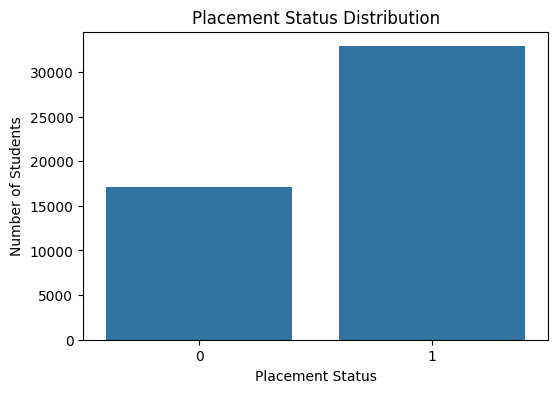

In [14]:
#Placement distribution
print(df["PlacementStatus"].value_counts())

plt.figure(figsize=(6,4))

sns.countplot(
    x="PlacementStatus",
    data=df
)

plt.title("Placement Status Distribution")
plt.xlabel("Placement Status")
plt.ylabel("Number of Students")

plt.show()

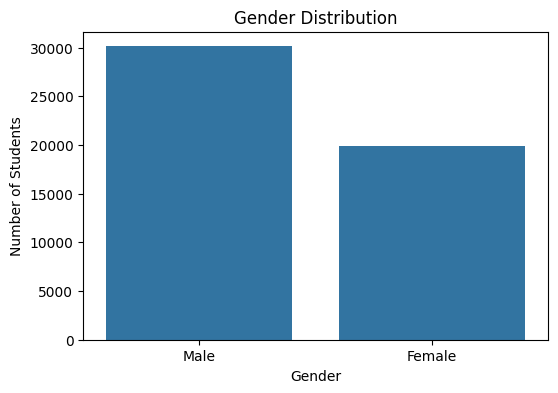

In [15]:
#Gender distribution
plt.figure(figsize=(6,4))

sns.countplot(
    x="Gender",
    data=df
)

plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Students")

plt.show()

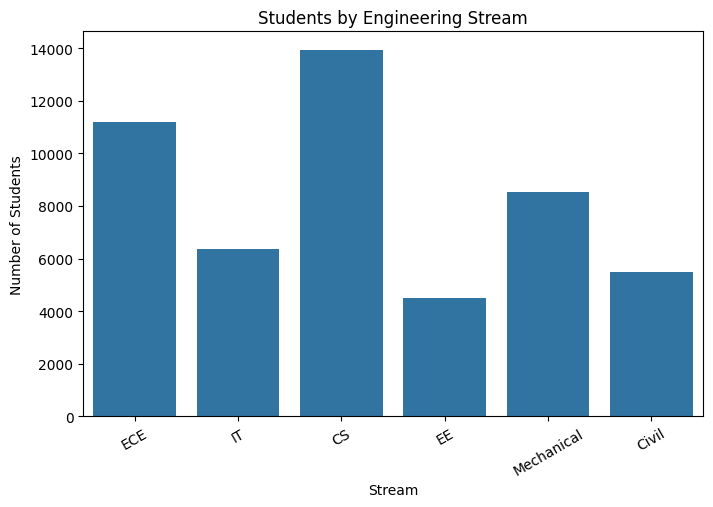

In [16]:
#Stream distribution
plt.figure(figsize=(8,5))

sns.countplot(
    x="Stream",
    data=df
)

plt.title("Students by Engineering Stream")
plt.xlabel("Stream")
plt.ylabel("Number of Students")

plt.xticks(rotation=30)

plt.show()

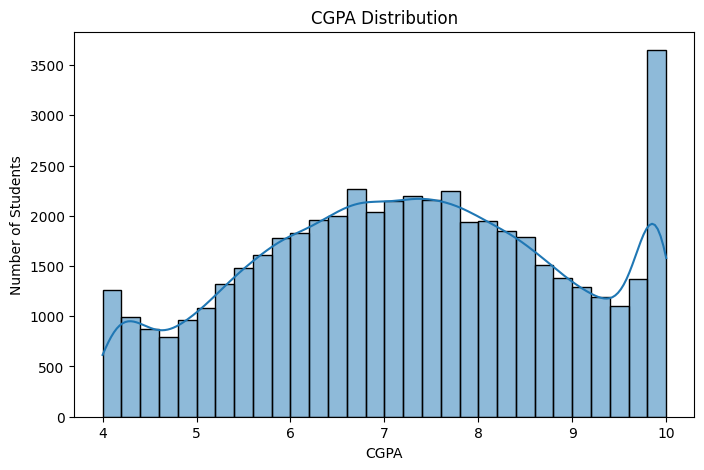

In [17]:
#CGPA distribution
plt.figure(figsize=(8,5))

sns.histplot(
    df["CGPA"],
    bins=30,
    kde=True
)

plt.title("CGPA Distribution")
plt.xlabel("CGPA")
plt.ylabel("Number of Students")

plt.show()

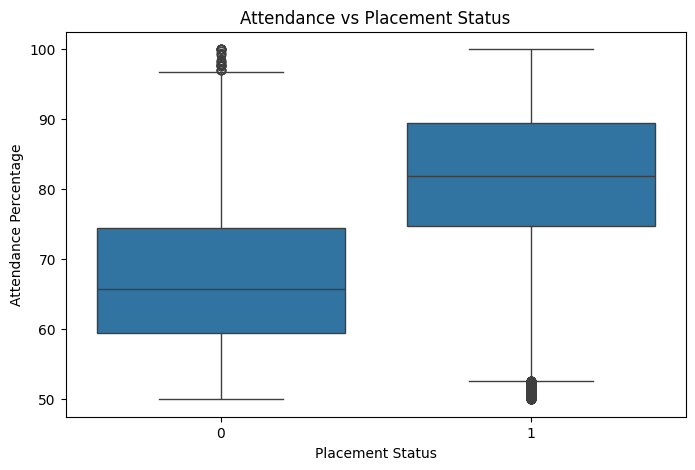

In [18]:
#Attendance vs Placement
plt.figure(figsize=(8,5))

sns.boxplot(
    x="PlacementStatus",
    y="AttendancePercent",
    data=df
)

plt.title("Attendance vs Placement Status")

plt.xlabel("Placement Status")
plt.ylabel("Attendance Percentage")

plt.show()

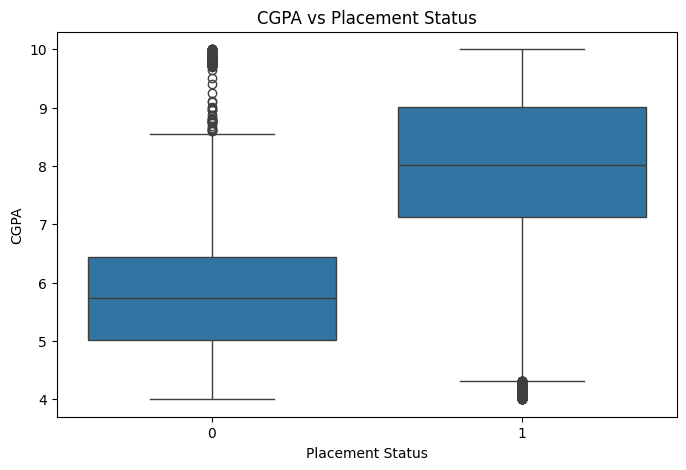

In [19]:
#5. CGPA vs Placement
plt.figure(figsize=(8,5))

sns.boxplot(
    x="PlacementStatus",
    y="CGPA",
    data=df
)

plt.title("CGPA vs Placement Status")

plt.xlabel("Placement Status")
plt.ylabel("CGPA")

plt.show()

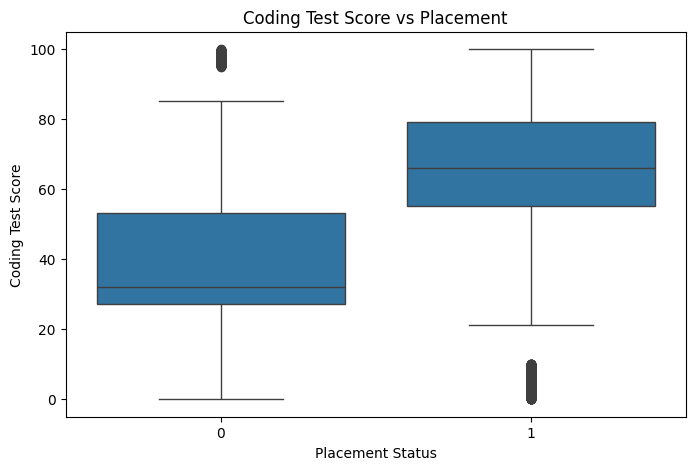

In [20]:
#6. Coding score vs placement
plt.figure(figsize=(8,5))

sns.boxplot(
    x="PlacementStatus",
    y="CodingTestScore",
    data=df
)

plt.title("Coding Test Score vs Placement")

plt.xlabel("Placement Status")
plt.ylabel("Coding Test Score")

plt.show()

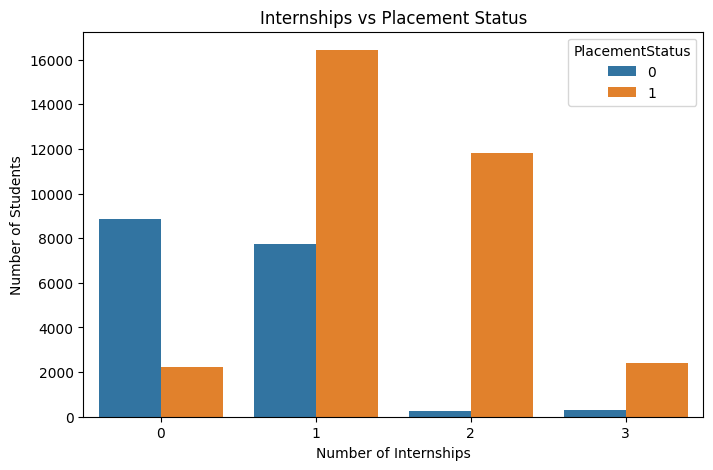

In [21]:
#7. Internship vs placement
plt.figure(figsize=(8,5))

sns.countplot(
    x="Internships",
    hue="PlacementStatus",
    data=df
)

plt.title("Internships vs Placement Status")
plt.xlabel("Number of Internships")
plt.ylabel("Number of Students")

plt.show()

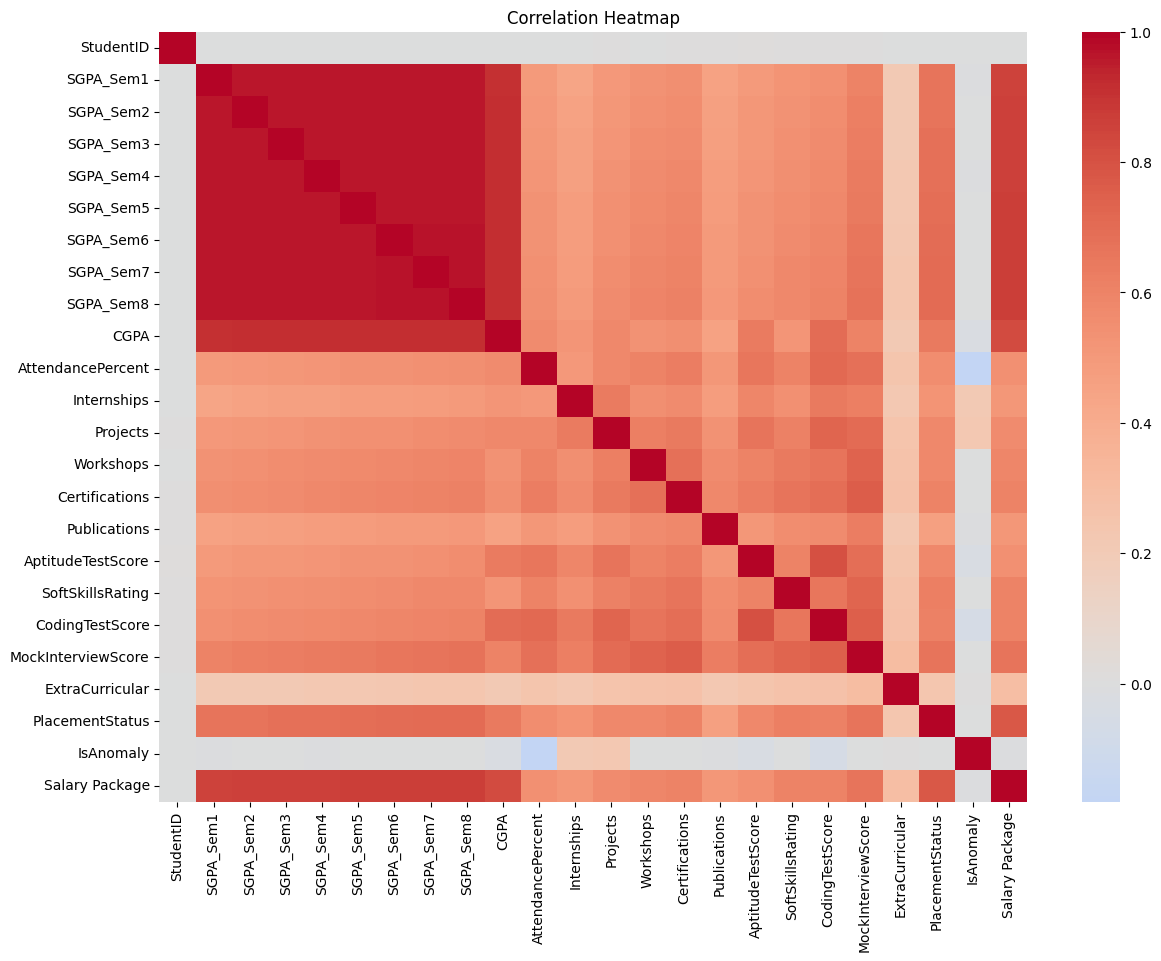

In [22]:
#8. Correlation heatmap
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(14,10))

sns.heatmap(
    numeric_df.corr(),
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap")

plt.show()

In [23]:
#9. Top correlations with placement
correlation = (
    numeric_df.corr()["PlacementStatus"]
    .sort_values(ascending=False)
)

print(correlation)

PlacementStatus       1.000000
Salary Package        0.774443
SGPA_Sem8             0.707147
SGPA_Sem7             0.701972
SGPA_Sem6             0.695881
SGPA_Sem5             0.690914
SGPA_Sem4             0.683972
SGPA_Sem3             0.677780
SGPA_Sem2             0.672252
MockInterviewScore    0.668000
SGPA_Sem1             0.665039
CGPA                  0.648926
SoftSkillsRating      0.624788
CodingTestScore       0.612832
Certifications        0.601315
Workshops             0.581535
Projects              0.580122
AptitudeTestScore     0.577749
AttendancePercent     0.554024
Internships           0.526197
Publications          0.469351
ExtraCurricular       0.239572
IsAnomaly             0.000009
StudentID            -0.001296
Name: PlacementStatus, dtype: float64


In [24]:
#Separate input and target
from sklearn.model_selection import train_test_split

# Remove columns that should not be used as predictors
X = df.drop(
    columns=[
        "PlacementStatus",
        "Salary Package",
        "StudentID",
        "IsAnomaly"
    ]
)

y = df["PlacementStatus"]

print("Input shape:", X.shape)
print("Target shape:", y.shape)

Input shape: (50000, 28)
Target shape: (50000,)


In [25]:
#Identify categorical and numerical columns
categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features = X.select_dtypes(
    exclude=["object"]
).columns.tolist()

print("Categorical Features:")
print(categorical_features)

print("\nNumerical Features:")
print(numerical_features)

Categorical Features:
['Gender', 'City', 'CollegeTier', 'Stream', 'Specialisation', 'Hostel', 'HistoryOfBacklogs', 'CGPA_Tier']

Numerical Features:
['SGPA_Sem1', 'SGPA_Sem2', 'SGPA_Sem3', 'SGPA_Sem4', 'SGPA_Sem5', 'SGPA_Sem6', 'SGPA_Sem7', 'SGPA_Sem8', 'CGPA', 'AttendancePercent', 'Internships', 'Projects', 'Workshops', 'Certifications', 'Publications', 'AptitudeTestScore', 'SoftSkillsRating', 'CodingTestScore', 'MockInterviewScore', 'ExtraCurricular']


In [26]:
#Preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.impute import SimpleImputer

In [27]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    (
        "numeric",
        numeric_pipeline,
        numerical_features
    ),
    (
        "categorical",
        categorical_pipeline,
        categorical_features
    )
])

In [28]:
#Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (40000, 28)
Testing data: (10000, 28)


In [29]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=150,
    max_depth=15,
    min_samples_split=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

In [30]:
from sklearn.pipeline import Pipeline

rf_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", model)
])

In [31]:
#Train the model
print("Training Random Forest...")

rf_pipeline.fit(
    X_train,
    y_train
)

print("Training completed successfully!")

Training Random Forest...
Training completed successfully!


In [32]:
#Predictions
y_pred = rf_pipeline.predict(X_test)

print("Predictions generated successfully!")
print(y_pred[:20])

Predictions generated successfully!
[0 0 1 1 1 1 1 1 1 1 0 0 1 1 0 1 0 1 1 0]


In [33]:
#2. Accuracy
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(
    y_test,
    y_pred
)

print("Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100)

Accuracy: 0.9174
Accuracy Percentage: 91.74


In [34]:
#3. Classification report
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred
    )
)

              precision    recall  f1-score   support

           0       0.88      0.88      0.88      3429
           1       0.94      0.94      0.94      6571

    accuracy                           0.92     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.92      0.92      0.92     10000



In [35]:
#4. Confusion matrix
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred
)

print(cm)

[[3017  412]
 [ 414 6157]]


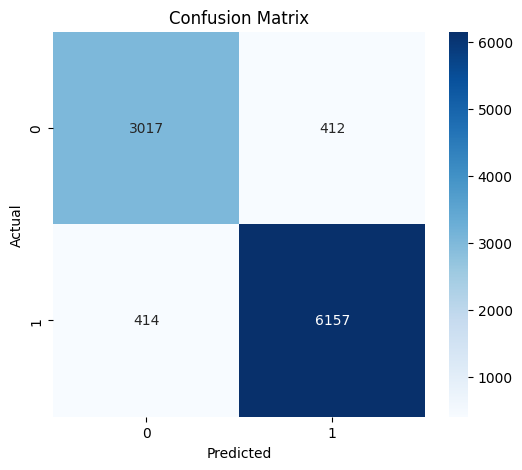

In [36]:
plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [37]:
#5. ROC-AUC
from sklearn.metrics import roc_auc_score

y_probability = rf_pipeline.predict_proba(
    X_test
)[:, 1]

roc_auc = roc_auc_score(
    y_test,
    y_probability
)

print("ROC-AUC Score:", roc_auc)

ROC-AUC Score: 0.9776613520377878


In [38]:
#1. Feature importance
feature_names = (
    rf_pipeline
    .named_steps["preprocessing"]
    .get_feature_names_out()
)

importance = (
    rf_pipeline
    .named_steps["classifier"]
    .feature_importances_
)

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

feature_importance = (
    feature_importance
    .sort_values(
        by="Importance",
        ascending=False
    )
    .head(15)
)

print(feature_importance)

                        Feature  Importance
7            numeric__SGPA_Sem8    0.108177
6            numeric__SGPA_Sem7    0.106902
4            numeric__SGPA_Sem5    0.093959
5            numeric__SGPA_Sem6    0.073214
18  numeric__MockInterviewScore    0.060522
8                 numeric__CGPA    0.055707
50   categorical__CGPA_Tier_Low    0.051395
3            numeric__SGPA_Sem4    0.048957
1            numeric__SGPA_Sem2    0.048860
11            numeric__Projects    0.044851
17     numeric__CodingTestScore    0.040955
16    numeric__SoftSkillsRating    0.039731
10         numeric__Internships    0.029175
2            numeric__SGPA_Sem3    0.028048
0            numeric__SGPA_Sem1    0.025723


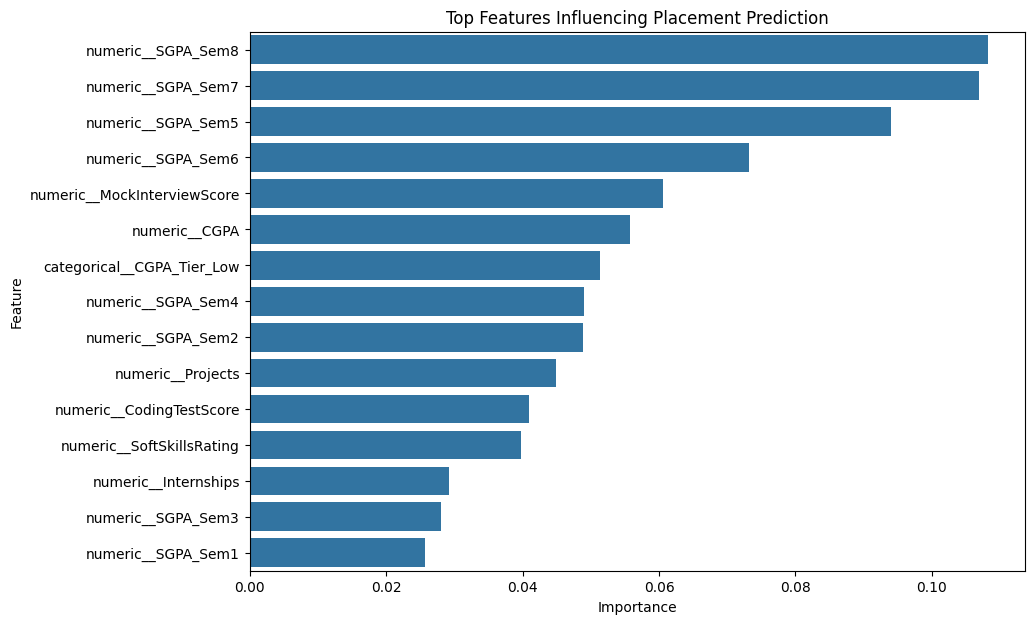

In [39]:
#2. Plot feature importance
plt.figure(figsize=(10,7))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title(
    "Top Features Influencing Placement Prediction"
)

plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

In [40]:
sample_student = X_test.iloc[[0]]

prediction = rf_pipeline.predict(
    sample_student
)[0]

probability = rf_pipeline.predict_proba(
    sample_student
)[0][1]

print("Predicted Placement Status:",
      "Placed" if prediction == 1 else "Not Placed")

print("Placement Probability:",
      round(probability * 100, 2), "%")

Predicted Placement Status: Not Placed
Placement Probability: 3.87 %
